# 02 · Cleaning, and comparing the raw and clean data

**Question:** what is wrong with the raw table, what does each cleaning rule fix, and how much data survives?

Each rule below is a function in `src/crimebase/` with a unit test; this notebook runs the same functions on
the real data, so the numbers here are the numbers the models see.

In [1]:
import numpy as np
import pandas as pd

from crimebase import viz
from crimebase.config import load_config

cfg = load_config()
pd.options.display.float_format = "{:,.3f}".format
pd.options.display.max_colwidth = 80
pd.options.display.width = 140

import pandas as pd
from crimebase.clean import KEY, PANEL_KEY, build_panel, dedupe_metrics, head_key
from crimebase.data import load_state_year
from crimebase.features import FEATURES, ID_COLUMNS, REASONS, build_matrix
from crimebase.splits import holdout_mask, train_mask, val_mask

raw = load_state_year(cfg)
keyed = raw.assign(head_key=head_key(raw.crime_head))
deduped = dedupe_metrics(keyed)
panel = build_panel(raw, cfg.task)
matrix = build_matrix(panel, cfg.task)

## 1. Raw against clean, stage by stage

In [2]:
eligible = matrix[matrix.eligible]
stages = pd.DataFrame(
    [
        ("raw state-year table", len(raw), raw.crime_head.nunique(), raw.disputed.mean()),
        ("head labels merged, duplicates resolved", len(deduped), deduped.head_key.nunique(), deduped.disputed.mean()),
        ("panel: one forecast series-year per row", len(panel), panel.head_key.nunique(), panel.disputed.mean()),
        ("eligible for a label", len(eligible), eligible.head_key.nunique(), eligible.disputed.mean()),
    ],
    columns=["stage", "rows", "distinct head labels", "disputed share"],
)
stages.style.format({"rows": "{:,}", "distinct head labels": "{:,}", "disputed share": "{:.1%}"})

,stage,rows,distinct head labels,disputed share
0,raw state-year table,"668,240","2,490",2.2%
1,"head labels merged, duplicates resolved","662,463","2,144",2.2%
2,panel: one forecast series-year per row,"316,299","2,031",4.1%
3,eligible for a label,"40,394",879,7.1%


The funnel is steep on purpose. The raw table has seven metrics per head; the panel keeps the one being
forecast (`cases_registered`) and joins the rest as features; most of what remains is zero or tiny and cannot
be forecast.

## 2. One head, many spellings

NCRB prints the same head in different case and punctuation across editions. `head_key` normalises them.

In [3]:
spellings = keyed.groupby("head_key").crime_head.nunique().sort_values(ascending=False)
print(f"{raw.crime_head.nunique():,} raw head labels collapse to {keyed.head_key.nunique():,} keys")
for key in spellings.index[:3]:
    variants = sorted(keyed.loc[keyed.head_key == key, "crime_head"].unique())
    print(f"\n{key!r} has {len(variants)} raw spellings, for example:")
    for v in variants[:4]:
        print("   ", v)

2,490 raw head labels collapse to 2,144 keys

'immoral traffic prevention act 1956' has 5 raw spellings, for example:
    IMMORAL TRAFFIC (PREVENTION) ACT, 1956
    IMMORAL TRAFFIC (PREVENTION) ACT,1956
    IMMORAL TRAFFIC PREVENTION ACT,1956
    Immoral Traffic (Prevention) Act 1956

'assault on women with intent to outrage her modesty' has 5 raw spellings, for example:
    ASSAULT ON WOMEN WITH INTENT TO OUTRAGE HER MODESTY
    Assault on Women with Intent to Outrage her Modesty
    Assault on Women with intent to outrage her Modesty
    Assault on women with intent to outrage her Modesty

'liquor narcotic drugs related acts | prohibition act state' has 4 raw spellings, for example:
    Liquor & Narcotic Drugs - Related Acts | Prohibition Act (State)
    Liquor & Narcotic Drugs Related Acts | Prohibition Act (State)
    Liquor & Narcotic Drugs ‐ Related Acts | Prohibition Act (State)
    Liquor & Narcotic Drugs – Related Acts | Prohibition Act (State)


## 3. Duplicates: keep the larger value, never sum

After merging spellings, some `(state, scope, head, year, metric)` keys have several raw rows.

In [4]:
groups = keyed.groupby(KEY).value.agg(rows="size", distinct="nunique", smallest="min", largest="max", total="sum")
dup = groups[groups.rows > 1]
differ = dup[dup.distinct > 1]
print(f"{len(dup):,} keys have more than one row; {(dup.distinct == 1).mean():.1%} of those carry identical values")
print(f"summing would have inflated {(dup.total > dup.largest).sum():,} of them; "
      f"the {len(differ)} that disagree are listed by how far apart they are:")
differ.assign(ratio=differ.largest / differ.smallest.replace(0, float('nan'))).sort_values("ratio", ascending=False).head(5)

5,743 keys have more than one row; 97.5% of those carry identical values
summing would have inflated 2,494 of them; the 141 that disagree are listed by how far apart they are:


,,,,,rows,distinct,smallest,largest,total,ratio
state_code,scope,head_key,year,metric,,,,,,
UP,scheduled_castes,sc st prev of atrocities act | for scs,2013,cases_registered,2,2,1.000,"1,847.000","1,848.000","1,847.000"
OD,scheduled_castes,sc st prev of atrocities act | for scs,2013,cases_registered,2,2,1.000,"1,785.000","1,786.000","1,785.000"
KA,scheduled_castes,sc st prev of atrocities act | for scs,2013,cases_registered,2,2,1.000,"1,380.000","1,381.000","1,380.000"
AP,scheduled_castes,sc st prev of atrocities act | for scs,2013,cases_registered,2,2,1.000,695.000,696.000,695.000
CG,sll,sc st prevention of atrocities act 1989,2010,persons_arrested,2,2,1.000,330.000,331.000,330.000


In [5]:
ap = keyed[(keyed.state_code == "AP") & (keyed.year == 2013) & (keyed.scope == "scheduled_castes")
           & keyed.head_key.str.startswith("sc st prev of atrocities act | for scs") & (keyed.metric == "cases_registered")]
print("raw rows (two source files disagree: 695 and 1):")
print(ap[["crime_head", "value", "disputed", "file"]].to_string(index=False))
kept = deduped[(deduped.state_code == "AP") & (deduped.year == 2013) & (deduped.scope == "scheduled_castes")
               & deduped.head_key.str.startswith("sc st prev of atrocities act | for scs") & (deduped.metric == "cases_registered")]
print("\nafter de-duplication:", kept.value.tolist())

raw rows (two source files disagree: 695 and 1):
                               crime_head   value  disputed                 file
SC/ST (Prev of Atrocities) Act | For SCs@ 695.000     False 4d3cea9e91d8f9b9.pdf
SC/ST (Prev. Of Atrocities) Act | For SCs   1.000     False 7bceb645d84f2fc3.pdf

after de-duplication: [695.0]


In [6]:
rows = keyed.merge(differ.reset_index()[KEY], on=KEY)
rows["row holds"] = np.where(rows.value == rows.groupby(KEY).value.transform("max"), "the larger value", "a smaller value")
evidence = rows.groupby("row holds").disputed.agg(rows="size", flagged_disputed="sum")
evidence["share flagged"] = evidence.flagged_disputed / evidence.rows
evidence.style.format({"share flagged": "{:.0%}"})

,rows,flagged_disputed,share flagged
row holds,,,
a smaller value,141,96,68%
the larger value,141,0,0%


Across all the disagreements the larger value is never flagged `disputed`, while a smaller one often is. The
dataset marks a value disputed when it is not the one most files report, so the larger value is the
consensus. That is why the rule is "keep the max", not "sum" or "average".

## 4. Rows that are not crime counts, and absurd values

The largest numbers in the panel are police call volumes, not crimes:

In [7]:
print(panel.nlargest(6, "cases")[["state_code", "scope", "head_key", "year", "cases"]].to_string(index=False))
complaints = matrix[matrix.head_key.str.startswith(tuple(cfg.task.non_crime_head_prefixes))]
print(f"\n{complaints.head_key.nunique()} heads / {len(complaints)} rows match the non-crime prefixes "
      f"{cfg.task.non_crime_head_prefixes}; years {complaints.year.min()}-{complaints.year.max()}")

state_code scope                                                                            head_key  year         cases
        DL   ipc             category of complaints received | distress call | over phone | dial 100  2013 8,904,862.000
        DL   ipc                                           oral complaints | total oral | complaints  2015 2,783,785.000
        UP   ipc                                           oral complaints | total oral | complaints  2015 2,776,370.000
        DL   ipc oral complaints | distress call | narrated to | over phone | o c sho | dial 100 etc  2015 2,761,889.000
        UP   ipc oral complaints | distress call | narrated to | over phone | o c sho | dial 100 etc  2015 2,696,707.000
        UP   sll                                                                                 sll  2015 2,549,421.000

10 heads / 486 rows match the non-crime prefixes ('oral complaints', 'category of complaints received'); years 2013-2015


Those heads ("Oral complaints", "Category of complaints received | Distress call ... Dial 100") are police
complaint-handling tables printed in the IPC scope, so they are marked ineligible.

## 5. A state that changes shape: Telangana leaves Andhra Pradesh

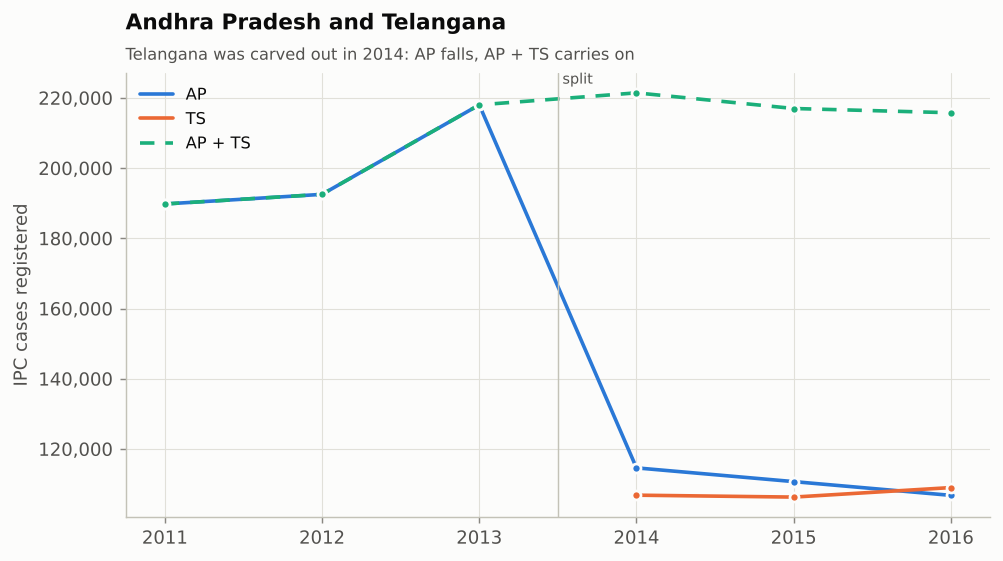

median next-year / this-year across AP heads (about 1 when nothing changes):
year
2011   0.950
2012   1.060
2013   0.530
2014   1.010
2015   0.940


In [8]:
total = panel[(panel.scope == "ipc") & (panel.head_key == "total cognizable ipc crimes")
              & panel.state_code.isin(["AP", "TS"]) & panel.year.between(2011, 2016)]
wide = total.pivot(index="year", columns="state_code", values="cases")
wide["AP + TS"] = wide["AP"] + wide["TS"].fillna(0)
viz.show(viz.plot_lines(wide, "Andhra Pradesh and Telangana", "IPC cases registered",
                        "Telangana was carved out in 2014: AP falls, AP + TS carries on",
                        dashed=("AP + TS",), annotate={2013.5: "split"}))
ap = matrix[(matrix.state_code == "AP") & (matrix.cases >= 100) & matrix.next_cases.notna()]
ratio = (ap.next_cases / ap.cases).groupby(ap.year).median()
print("median next-year / this-year across AP heads (about 1 when nothing changes):")
print(ratio.loc[2011:2015].round(2).to_string())

A fall of nearly half in one year is a boundary change, not a crime trend, so AP's 2013 rows are excluded
(configured in `configs/crimebase.yaml`). The same logic drops pairs that jump more than 10× (a changed
definition) or switch between the two sources the table is built from.

## 6. How many rows get a label, and why not

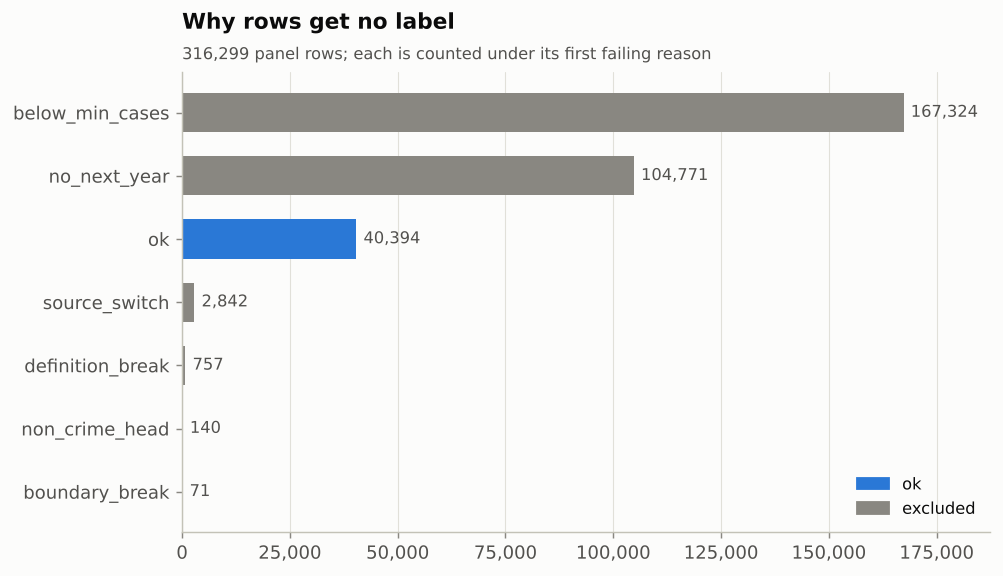

,rows,share
reason,,
below_min_cases,"167,324",52.9%
no_next_year,"104,771",33.1%
ok,"40,394",12.8%
source_switch,"2,842",0.9%
definition_break,757,0.2%
non_crime_head,140,0.0%
boundary_break,71,0.0%


In [9]:
counts = matrix.reason.value_counts()
viz.show(viz.plot_counts(counts, "Why rows get no label", f"{len(matrix):,} panel rows; each is counted under its first failing reason", highlight="ok"))
counts.to_frame("rows").assign(share=lambda d: d.rows / d.rows.sum()).style.format({"rows": "{:,}", "share": "{:.1%}"})

Most rows are excluded because the count is below the minimum (`min_cases`, 50) or because it is a series'
last year. Notebook 04 shows how the results move when that minimum changes.

## 7. The labels

`y_trend` is `down` below −10%, `stable` within ±10%, `up` above +10% (growth from year *t* to *t+1*).

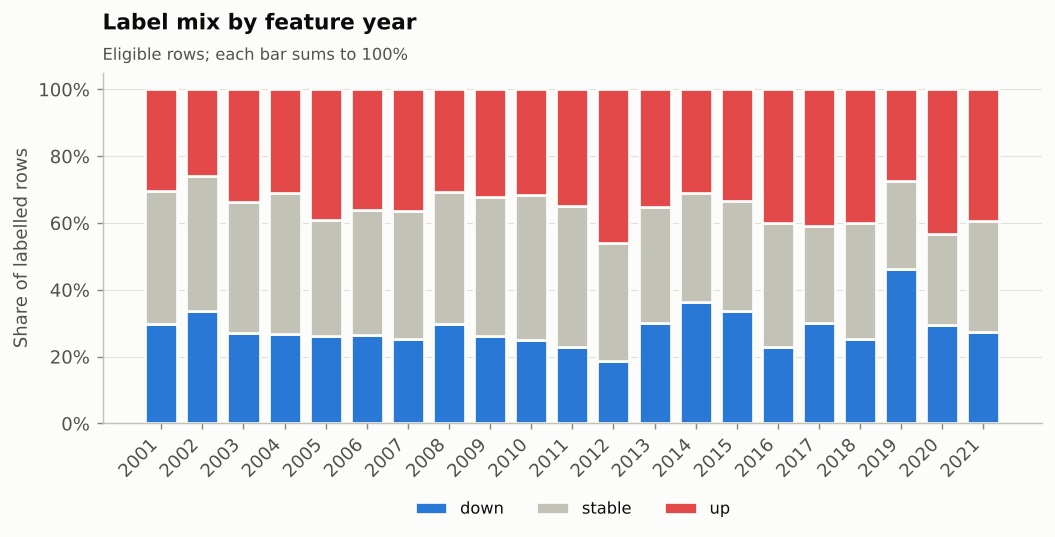

,feature years,rows,down,stable,up
train,<= 2016,24114,28.0%,38.1%,33.8%
validation,2017-2018,4012,28.2%,31.2%,40.6%
test (held out),>= 2019,12268,32.8%,29.8%,37.3%


In [10]:
elig = matrix[matrix.eligible]
names = {0: "down", 1: "stable", 2: "up"}
mix = pd.crosstab(elig.year, elig.y_trend.map(names), normalize="index")[["down", "stable", "up"]]
viz.show(viz.plot_label_mix(mix, "Label mix by feature year", "Eligible rows; each bar sums to 100%"))

s = cfg.split
sizes = pd.DataFrame({
    "feature years": [f"<= {s.train_to}", f"{s.val_years[0]}-{s.val_years[-1]}", f">= {s.test_from}"],
    "rows": [int(f(matrix, s, "y_trend").sum()) for f in (train_mask, val_mask, holdout_mask)],
}, index=["train", "validation", "test (held out)"])
for k, name in names.items():
    sizes[name] = [
        f"{(matrix.loc[f(matrix, s, 'y_trend'), 'y_trend'] == k).mean():.1%}" for f in (train_mask, val_mask, holdout_mask)
    ]
sizes

The classes are reasonably balanced, so no resampling is needed (the models use balanced class weights as a
cheap safeguard). The mix does move between years, notably around 2019-2020, which is one reason the test
years are kept strictly after the training years.

## 8. No peeking: checking for leakage on the real data

Features for year *t* must not depend on anything after *t*. The unit tests prove this on synthetic data;
this cell proves it on the real panel by rewriting every count after 2014 (multiplying by 7) and checking that
no feature at or before 2014 changes.

In [11]:
cutoff = 2014
rewritten = panel.copy()
rewritten.loc[rewritten.year > cutoff, "cases"] *= 7
other = build_matrix(rewritten, cfg.task)
cols = [*ID_COLUMNS, *FEATURES]
before = matrix.loc[matrix.year <= cutoff, cols].reset_index(drop=True)
after = other.loc[other.year <= cutoff, cols].reset_index(drop=True)
try:
    pd.testing.assert_frame_equal(before, after)
    print(f"OK: {len(before):,} rows x {len(FEATURES)} features at or before {cutoff} are identical "
          f"after rewriting every later year")
except AssertionError as err:
    print("LEAK:", err)

OK: 107,947 rows x 29 features at or before 2014 are identical after rewriting every later year


## Summary

| Rule | Evidence | Effect |
|---|---|---|
| Merge head spellings | 2,490 labels → 2,144 keys | series continue across editions |
| De-duplicate by max, never sum | 97.5% of duplicate keys identical; larger value is the real one | no double counting |
| Never aggregate across scopes | rape in MH 2021 adds to 2.3× the IPC figure (notebook 01) | each (scope, head) is its own series |
| Drop police-complaint heads | values up to 8.9 million in 2013-2015 | not crime counts |
| Drop boundary changes | AP falls by half when Telangana leaves | not a crime trend |
| Drop 10× jumps and source switches | definition changes | label noise removed |
| Minimum count | count below 50 is mostly noise | configurable, studied in notebook 04 |

Rows are **flagged, not deleted**, so every exclusion above stays countable in the model matrix.